In [2]:

import json
import random as rd
import sys
import time
import string
import itertools as it
from collections import ChainMap
from concurrent.futures import ProcessPoolExecutor
from math import ceil, erf, log10
from pathlib import Path
from typing import Callable, Tuple

import matplotlib.color_data as mcd
import matplotlib.gridspec as gridspec
import matplotlib.lines as lines
import matplotlib.patches as mpatch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.integrate as sp
import scipy.stats
from scipy.stats import qmc
import seaborn as sns
from assimulo.problem import Explicit_Problem
from assimulo.solvers import CVode
from lmfit import Parameter, Parameters, minimize, report_fit
from matplotlib import cm
from mpl_toolkits.mplot3d import axes3d
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import ListedColormap
from SALib.analyze import morris, sobol
from SALib.plotting.bar import plot as barplot
from SALib.plotting.hdmr import plot as hdmrplot
from SALib.sample import saltelli, fast_sampler, sobol_sequence
from SALib.test_functions import Ishigami
from scipy.interpolate import lagrange
from scipy.linalg import null_space
from tqdm import tqdm, trange


import scienceplots
plt.style.use("default")
#plt.style.use('science')


#plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.weight"] = "bold"
# plt.rcParams["axes.labelweight"] = "bold"
# plt.rcParams['axes.titlepad'] = 23
plt.rcParams.update({'figure.dpi': '300'})
plt.rcParams.update({
    "font.family": "serif",   # specify font family here
    "font.serif": ["Times"],  # specify font here
    "font.size":11}) 

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cols = [f"{color}" for color in colors]
plt.rc('xtick',labelsize=20)
plt.rc('ytick',labelsize=20)
#plt.patch.set_alpha(0.0)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

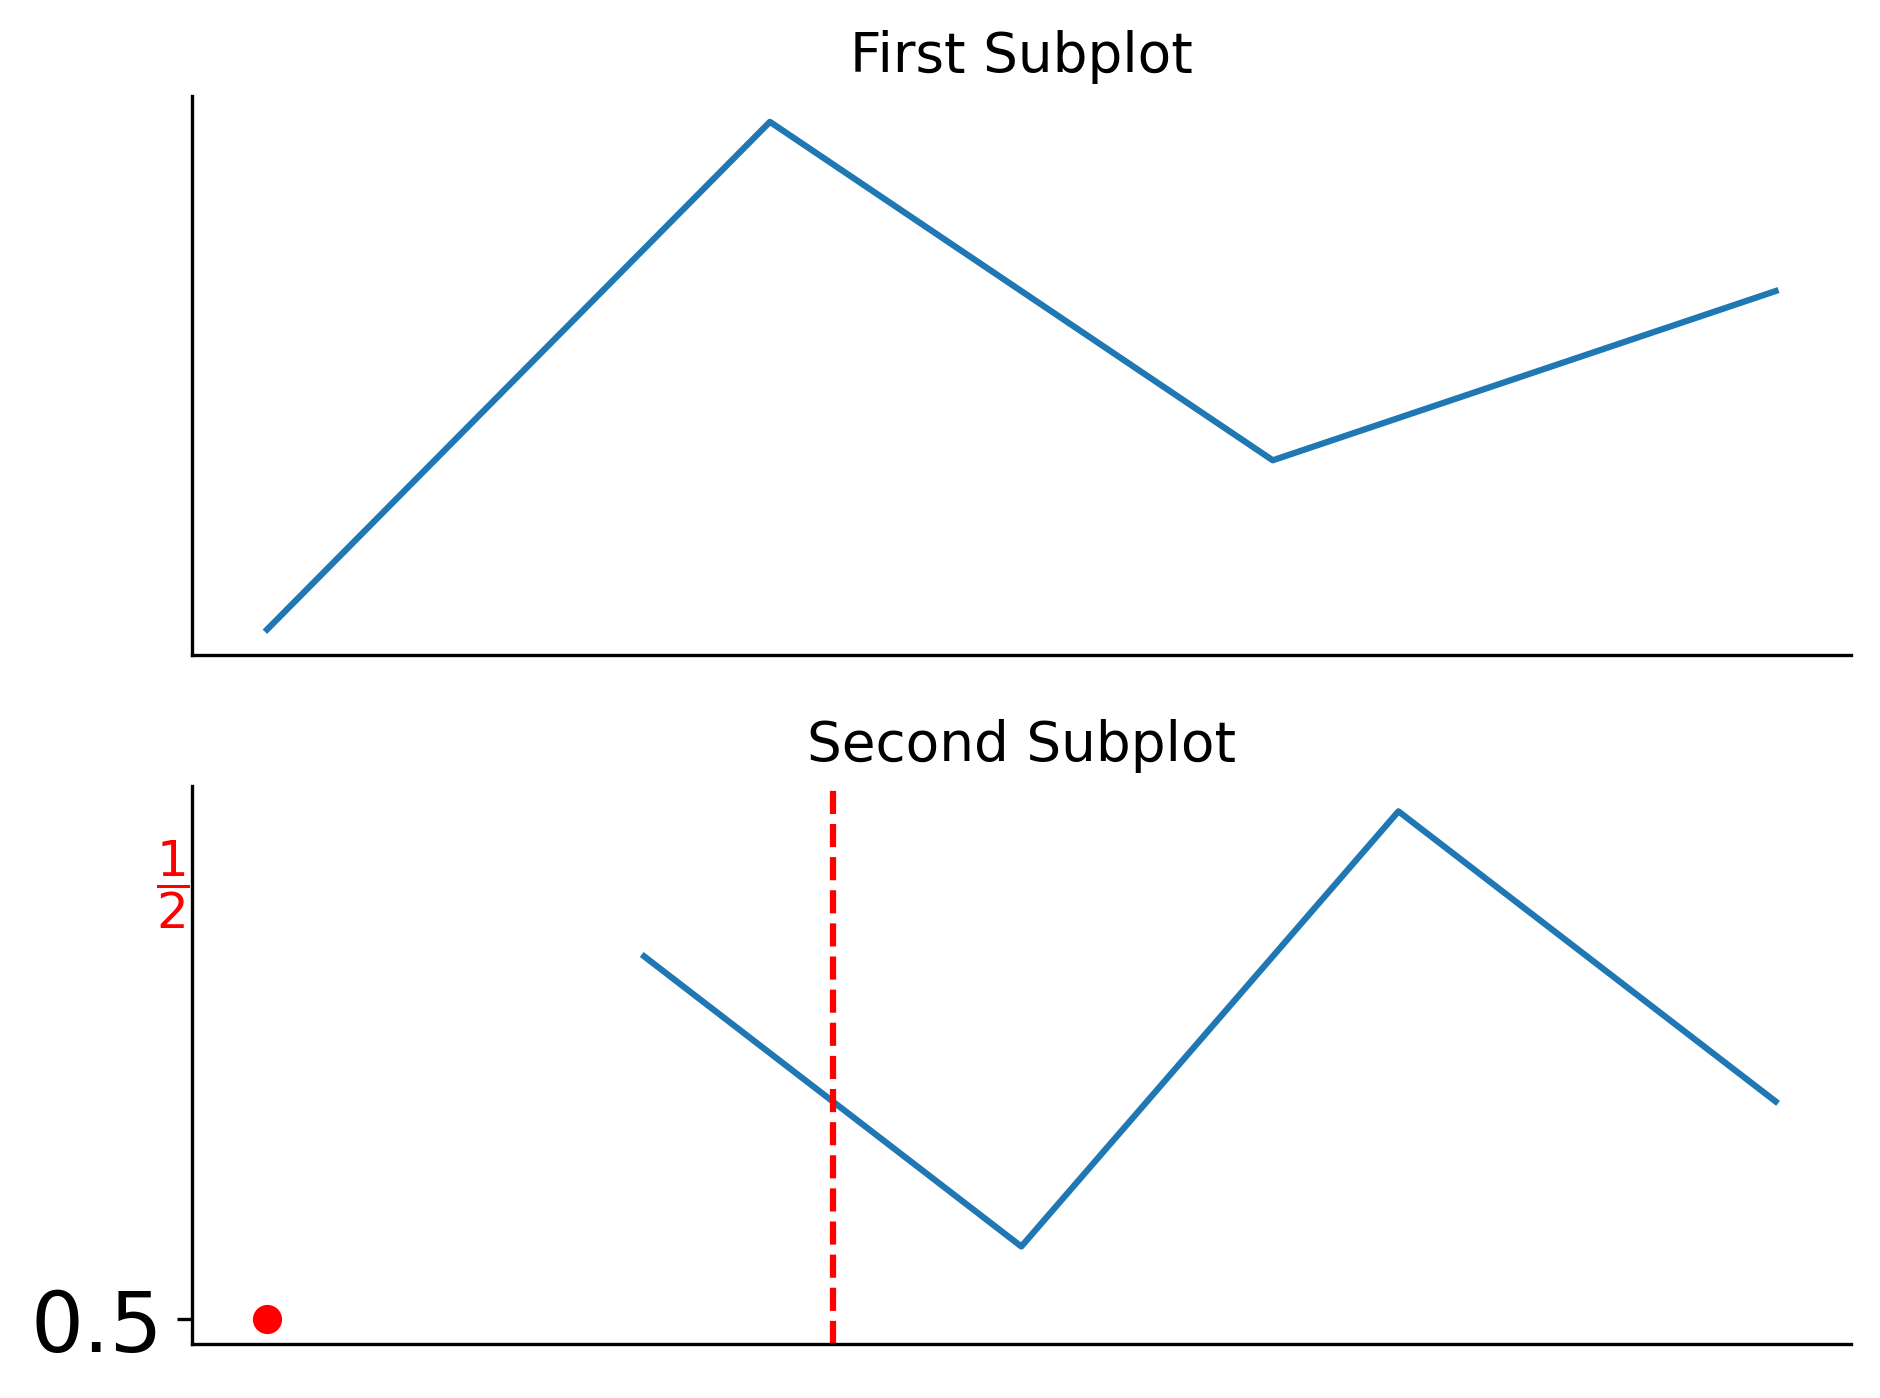

In [26]:
import matplotlib.pyplot as plt
# Create the figure and two subplots
fig, (ax1, ax2) = plt.subplots(2, 1)

# Plot data on the first subplot
ax1.plot([1, 2, 3, 4], [1, 4, 2, 3])
ax1.set_title('First Subplot')
top_side1 = ax1.spines["top"]
top_side1.set_visible(False)
top_side2 = ax2.spines["top"]
top_side2.set_visible(False)


right_side1 = ax1.spines["right"]
right_side1.set_visible(False)
right_side2 = ax2.spines["right"]
right_side2.set_visible(False)

# Plot data on the second subplot
ax2.plot([1, 2, 3, 4], [3, 1, 4, 2])
ax2.set_title('Second Subplot')


ax1.set_xticks([])
ax1.set_yticks([])
ax2.set_xticks([])
ax2.set_yticks([])


# Create a vertical dashed line that goes from the top to the bottom subplot
line_pos = 1.5  # position of the vertical line
plt.axvline(x=line_pos, ymin=0, ymax=5, color='r', linestyle='--')

# Add a dot at 1/2 on the y-axis
dot_pos = 0.5  # position of the dot
plt.plot([0], [dot_pos], marker='o', color='r')

# Set the y-tick labels and positions
y_ticks = ax1.get_yticks()
y_ticklabels = [f'{t:.1f}' for t in y_ticks]
y_ticks = list(y_ticks) + [dot_pos]
y_ticklabels = y_ticklabels + [f'{dot_pos:.1f}']

# Set the y-tick positions and labels for both subplots
ax1.set_yticks(y_ticks)
ax1.set_yticklabels(y_ticklabels)
ax2.set_yticks(y_ticks)
ax2.set_yticklabels(y_ticklabels)


# Add text at a particular location
text = r"$\dfrac{1}{2}$"
x_pos = -1/4  # x-coordinate of the text
y_pos = 3.5  # y-coordinate of the text
ax2.text(x_pos, y_pos, text, fontsize=12, ha='center', va='center', color='r')

# Adjust the layout and display the figure
fig.tight_layout()
plt.show()